# Partial Exam PMP · 21.11.2025 · Worked Solution

**Time:** 60 minutes. **Upload:** code + screenshots of the executions + graphs, in a folder
named **`Partial`** in your GitHub repository.

> How to use this notebook: read it once, then close it and write both subjects from scratch
> in a new notebook with only `CHEAT_SHEET.md` open, timing yourself (≈ 25 min per subject +
> 10 min for screenshots and the upload).

| Subject | Points |
|---|---|
| 1.a Build the network · 1.b Inference · 1.c Independence | 4 · 5 · 4 |
| 2.a Model · 2.b Forward · 2.c Viterbi · 2.d Simulation | 4 · 4 · 4 · 4 |

In [1]:
%pip install -q pgmpy hmmlearn networkx matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from itertools import product
from pathlib import Path

from pgmpy.models import DiscreteBayesianNetwork       # (older pgmpy: BayesianNetwork)
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination
from hmmlearn import hmm

FIG = Path("figures")
FIG.mkdir(exist_ok=True)

---
# Subject 1 · Smart Home Energy and Comfort System

Variables: OutsideTemp **O** {cold, mild}, HeatingOn **H** {yes, no}, WindowOpen **W** {yes, no},
RoomTemp **R** {warm, cool}, EnergyUse **E** {high, low}, Comfort **C** {comfortable, uncomfortable}.

From the CPTs we read the parents of every node:
O → H, O → W, (H, W) → R, H → E, R → C.

$$P(O,H,W,R,E,C) = P(O)\,P(H\mid O)\,P(W\mid O)\,P(R\mid H,W)\,P(E\mid H)\,P(C\mid R)$$

## 1.a Build the Bayesian network

In [3]:
# Structure: (parent, child)
model = DiscreteBayesianNetwork([
    ("O", "H"), ("O", "W"),
    ("H", "R"), ("W", "R"),
    ("H", "E"),
    ("R", "C"),
])

# CPDs. Rows = states of the child (in the order of state_names).
# Columns = combinations of the parents; the LAST parent in `evidence` changes fastest.
cpd_o = TabularCPD("O", 2, [[0.3], [0.7]],
                   state_names={"O": ["cold", "mild"]})

cpd_h = TabularCPD("H", 2,
                   #  O=cold  O=mild
                   [[0.9,    0.2],     # H = yes
                    [0.1,    0.8]],    # H = no   (1 - the row above)
                   evidence=["O"], evidence_card=[2],
                   state_names={"H": ["yes", "no"], "O": ["cold", "mild"]})

cpd_w = TabularCPD("W", 2,
                   [[0.1, 0.6],        # W = yes
                    [0.9, 0.4]],       # W = no
                   evidence=["O"], evidence_card=[2],
                   state_names={"W": ["yes", "no"], "O": ["cold", "mild"]})

cpd_r = TabularCPD("R", 2,
                   #  H=yes,W=yes  H=yes,W=no  H=no,W=yes  H=no,W=no
                   [[0.6,          0.9,        0.3,        0.5],    # R = warm
                    [0.4,          0.1,        0.7,        0.5]],   # R = cool
                   evidence=["H", "W"], evidence_card=[2, 2],
                   state_names={"R": ["warm", "cool"], "H": ["yes", "no"], "W": ["yes", "no"]})

cpd_e = TabularCPD("E", 2,
                   [[0.8, 0.2],        # E = high   (columns: H = yes, H = no)
                    [0.2, 0.8]],       # E = low
                   evidence=["H"], evidence_card=[2],
                   state_names={"E": ["high", "low"], "H": ["yes", "no"]})

cpd_c = TabularCPD("C", 2,
                   [[0.85, 0.40],      # C = comfortable   (columns: R = warm, R = cool)
                    [0.15, 0.60]],     # C = uncomfortable
                   evidence=["R"], evidence_card=[2],
                   state_names={"C": ["comfortable", "uncomfortable"], "R": ["warm", "cool"]})

model.add_cpds(cpd_o, cpd_h, cpd_w, cpd_r, cpd_e, cpd_c)
print("Model OK:", model.check_model())     # raises an error if a column does not sum to 1
print(cpd_r)

Model OK: True
+---------+--------+--------+--------+-------+
| H       | H(yes) | H(yes) | H(no)  | H(no) |
+---------+--------+--------+--------+-------+
| W       | W(yes) | W(no)  | W(yes) | W(no) |
+---------+--------+--------+--------+-------+
| R(warm) | 0.6    | 0.9    | 0.3    | 0.5   |
+---------+--------+--------+--------+-------+
| R(cool) | 0.4    | 0.1    | 0.7    | 0.5   |
+---------+--------+--------+--------+-------+


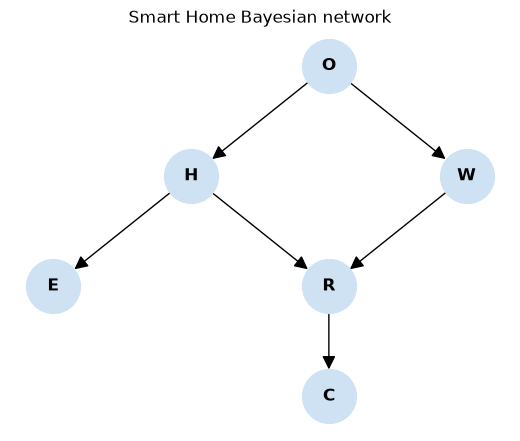

In [4]:
# The graph (requested in 1.a) - saved as PNG for the upload
pos = {"O": (0, 2), "H": (-1, 1), "W": (1, 1), "R": (0, 0), "E": (-2, 0), "C": (0, -1)}
plt.figure(figsize=(5, 4))
nx.draw(nx.DiGraph(model.edges()), pos, with_labels=True, node_size=1500,
        node_color="#cfe2f3", arrowsize=20, font_weight="bold")
plt.title("Smart Home Bayesian network")
plt.savefig(FIG / "subject1_network.png", dpi=150, bbox_inches="tight")
plt.show()

## 1.b Inference with Variable Elimination

In [5]:
infer = VariableElimination(model)
evidence = {"C": "comfortable"}

# P(H | C = comfortable)
q_h = infer.query(["H"], evidence=evidence, show_progress=False)
print(q_h)
print(f"P(H = yes | C = comfortable) = {q_h.get_value(H='yes'):.4f}\n")

# P(E | C = comfortable)
q_e = infer.query(["E"], evidence=evidence, show_progress=False)
print(q_e)
print(f"P(E = high | C = comfortable) = {q_e.get_value(E='high'):.4f}")

+--------+----------+
| H      |   phi(H) |
+========+==========+
| H(yes) |   0.4823 |
+--------+----------+
| H(no)  |   0.5177 |
+--------+----------+
P(H = yes | C = comfortable) = 0.4823

+---------+----------+
| E       |   phi(E) |
+=========+==========+
| E(high) |   0.4894 |
+---------+----------+
| E(low)  |   0.5106 |
+---------+----------+
P(E = high | C = comfortable) = 0.4894


In [6]:
# MAP of (H, W) jointly: maximise P(H, W | C = comfortable) over the 4 combinations
map_hw = infer.map_query(["H", "W"], evidence=evidence, show_progress=False)
print("MAP (H, W) | C = comfortable:", map_hw)

# The full joint table, to justify the answer
print(infer.query(["H", "W"], evidence=evidence, show_progress=False))

MAP (H, W) | C = comfortable: {'W': 'no', 'H': 'yes'}
+--------+--------+------------+
| H      | W      |   phi(H,W) |
+========+========+============+
| H(yes) | W(yes) |     0.1138 |
+--------+--------+------------+
| H(yes) | W(no)  |     0.3684 |
+--------+--------+------------+
| H(no)  | W(yes) |     0.2776 |
+--------+--------+------------+
| H(no)  | W(no)  |     0.2401 |
+--------+--------+------------+


### Checking 1.b by hand
1. Sum out O: $P(H,W) = \sum_o P(o)P(H\mid o)P(W\mid o)$

| H \ W | yes | no |
|---|---|---|
| yes | 0.3·0.9·0.1 + 0.7·0.2·0.6 = **0.111** | 0.3·0.9·0.9 + 0.7·0.2·0.4 = **0.299** |
| no | 0.3·0.1·0.1 + 0.7·0.8·0.6 = **0.339** | 0.3·0.1·0.9 + 0.7·0.8·0.4 = **0.251** |

2. $P(C{=}c\mid H,W) = 0.85\,P(\text{warm}\mid H,W) + 0.40\,(1-P(\text{warm}\mid H,W))$
   → (yes,yes) 0.67, (yes,no) 0.805, (no,yes) 0.535, (no,no) 0.625.
3. Multiply: $P(H,W,C{=}c)$ = 0.07437, 0.24070, 0.18137, 0.15688; sum $P(C{=}c) = 0.65330$.

| Question | Answer |
|---|---|
| $P(H{=}yes\mid C{=}c)$ | (0.07437 + 0.24070) / 0.65330 = **0.4823** |
| $P(E{=}high\mid C{=}c)$ | 0.8·0.4823 + 0.2·0.5177 = **0.4894** (E depends only on H) |
| MAP (H, W) | **H = yes, W = no**, $P = 0.3684$ |

Notice: the joint MAP has H = yes, but the *marginal* maximum of H is "no" (0.5177).
A joint MAP is **not** the combination of marginal maxima – use `map_query` with both variables.

## 1.c Independence (d-separation)
Rules: a chain or fork is **blocked** when the middle node is observed; a collider is
**blocked** unless the collider or one of its descendants is observed.

**Is W ⊥ E | H? Yes.** Paths between W and E:
- W ← O → H → E: H is observed in a chain (O → H → E) ⇒ blocked.
- W → R ← H → E: R is a collider; neither R nor its descendant C is observed ⇒ blocked.

All paths are blocked ⇒ W and E are d-separated by H ⇒ independent.

**Are O and C independent given R? Yes.** C's only parent is R, so every path from O to C ends in
… → R → C. R is observed and sits in a chain there ⇒ every path is blocked.

In [7]:
# is_dconnected = True means there is an active path, i.e. NOT independent
print("W ⊥ E | H ?", not model.is_dconnected("W", "E", observed=["H"]))
print("O ⊥ C | R ?", not model.is_dconnected("O", "C", observed=["R"]))

W ⊥ E | H ? True
O ⊥ C | R ? True


---
# Subject 2 · Activity prediction with an HMM

Hidden states: Walking (W), Running (R), Resting (S). Observations: Low (L), Medium (M), High (H).

## 2.a Model construction

In [8]:
states = ["Walking", "Running", "Resting"]
symbols = ["Low", "Medium", "High"]

pi = np.array([0.4, 0.3, 0.3])                 # initial probabilities
A = np.array([[0.6, 0.3, 0.1],                 # from Walking  -> W, R, S
              [0.2, 0.7, 0.1],                 # from Running
              [0.3, 0.2, 0.5]])                # from Resting
B = np.array([[0.10, 0.70, 0.20],              # Walking emits L, M, H
              [0.05, 0.25, 0.70],              # Running
              [0.80, 0.15, 0.05]])             # Resting
assert np.allclose(A.sum(1), 1) and np.allclose(B.sum(1), 1)

# CategoricalHMM: discrete observations (in hmmlearn < 0.3 this was MultinomialHMM)
hmm_model = hmm.CategoricalHMM(n_components=3, init_params="", params="")
hmm_model.n_features = 3
hmm_model.startprob_ = pi
hmm_model.transmat_ = A
hmm_model.emissionprob_ = B

# Observations as integers in a column: Medium, High, Low -> [[1], [2], [0]]
seq = [symbols.index(s) for s in ["Medium", "High", "Low"]]
X = np.array(seq).reshape(-1, 1)
print("encoded sequence:", X.ravel())

encoded sequence: [1 2 0]


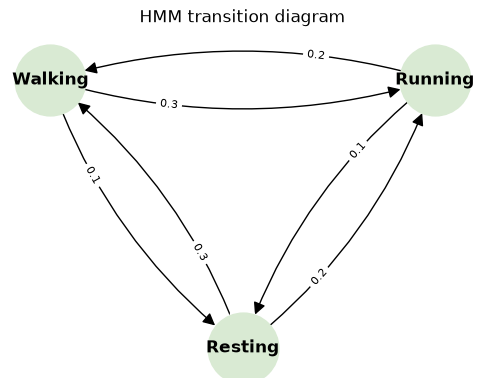

In [9]:
# State diagram (useful as a "relevant graph" for the upload)
G = nx.DiGraph()
for i, j in product(range(3), range(3)):
    G.add_edge(states[i], states[j], p=A[i, j])
pos = {"Walking": (0, 1), "Running": (2, 1), "Resting": (1, -0.6)}
plt.figure(figsize=(6, 4.5))
nx.draw_networkx_nodes(G, pos, node_size=2600, node_color="#d9ead3")
nx.draw_networkx_labels(G, pos, font_weight="bold")
nx.draw_networkx_edges(G, pos, arrowsize=18, connectionstyle="arc3,rad=0.15", node_size=2600)
nx.draw_networkx_edge_labels(G, pos, {(u, v): f"{d['p']:.1f}" for u, v, d in G.edges(data=True)},
                             connectionstyle="arc3,rad=0.15", label_pos=0.3, font_size=8)
plt.axis("off")
plt.title("HMM transition diagram")
plt.savefig(FIG / "subject2_diagram.png", dpi=150, bbox_inches="tight")
plt.show()

## 2.b Forward algorithm
$\alpha_1(j) = \pi_j b_j(o_1)$, $\alpha_t(j) = b_j(o_t)\sum_i\alpha_{t-1}(i)a_{ij}$, $P(o) = \sum_j\alpha_T(j)$.

| t | α(W) | α(R) | α(S) |
|---|---|---|---|
| 1 (M) | 0.4·0.7 = 0.28 | 0.3·0.25 = 0.075 | 0.3·0.15 = 0.045 |
| 2 (H) | 0.2·(0.28·0.6 + 0.075·0.2 + 0.045·0.3) = 0.0393 | 0.7·(0.28·0.3 + 0.075·0.7 + 0.045·0.2) = 0.10185 | 0.05·(0.028 + 0.0075 + 0.0225) = 0.0029 |
| 3 (L) | 0.004482 | 0.004183 | 0.012452 |

**P(M, H, L) = 0.021117**

In [10]:
# Forward by hand (vector form)
alpha = np.zeros((len(seq), 3))
alpha[0] = pi * B[:, seq[0]]                          # initialisation
for t in range(1, len(seq)):
    alpha[t] = B[:, seq[t]] * (alpha[t - 1] @ A)      # recursion
p_forward = alpha[-1].sum()                           # termination
print("alpha table (rows = t, columns = W, R, S):\n", np.round(alpha, 6))
print(f"P(M, H, L) manual Forward  = {p_forward:.6f}")

# hmmlearn: score() returns the LOG-probability computed with Forward
print(f"P(M, H, L) hmmlearn score  = {np.exp(hmm_model.score(X)):.6f}")

alpha table (rows = t, columns = W, R, S):
 [[0.28     0.075    0.045   ]
 [0.0393   0.10185  0.0029  ]
 [0.004482 0.004183 0.012452]]
P(M, H, L) manual Forward  = 0.021117
P(M, H, L) hmmlearn score  = 0.021117


## 2.c Viterbi algorithm

In [11]:
log_p, best_path = hmm_model.decode(X, algorithm="viterbi")
print("Most likely hidden states:", [states[s] for s in best_path])
print(f"P(best path, observations) = {np.exp(log_p):.6f}")
print(f"P(best path | observations) = {np.exp(log_p) / p_forward:.4f}")

# Check against brute force over the 3^3 = 27 paths (only possible because T is tiny)
def joint(path):
    p = pi[path[0]] * B[path[0], seq[0]]
    for t in range(1, len(seq)):
        p *= A[path[t - 1], path[t]] * B[path[t], seq[t]]
    return p
bf = max(product(range(3), repeat=3), key=joint)
print("Brute force agrees:", [states[s] for s in bf], f"{joint(bf):.6f}")

Most likely hidden states: ['Walking', 'Running', 'Resting']
P(best path, observations) = 0.004704
P(best path | observations) = 0.2228
Brute force agrees: ['Walking', 'Running', 'Resting'] 0.004704


**Why Viterbi instead of brute force for long sequences?** Brute force enumerates all $N^T$
paths – exponential (with T = 100 that is $3^{100}$). Viterbi uses dynamic programming: at each time
it keeps only the best path ending in each state, so it costs $O(T\,N^2)$ – linear in T.

## 2.d Simulation: 10,000 sequences

In [12]:
N = 10_000
rng = np.random.default_rng(42)
hits = 0
running_estimate = np.empty(N)
for k in range(N):
    obs, _ = hmm_model.sample(3, random_state=rng.integers(1_000_000_000))  # one sequence of length 3
    hits += np.array_equal(obs.ravel(), seq)                                 # is it [M, H, L]?
    running_estimate[k] = hits / (k + 1)

p_empirical = hits / N
std_error = np.sqrt(p_forward * (1 - p_forward) / N)
print(f"empirical P(M,H,L) = {hits}/{N} = {p_empirical:.4f}")
print(f"exact (Forward)    = {p_forward:.4f}")
print(f"difference = {abs(p_empirical - p_forward):.4f}  (standard error ≈ {std_error:.4f})")

empirical P(M,H,L) = 193/10000 = 0.0193
exact (Forward)    = 0.0211
difference = 0.0018  (standard error ≈ 0.0014)


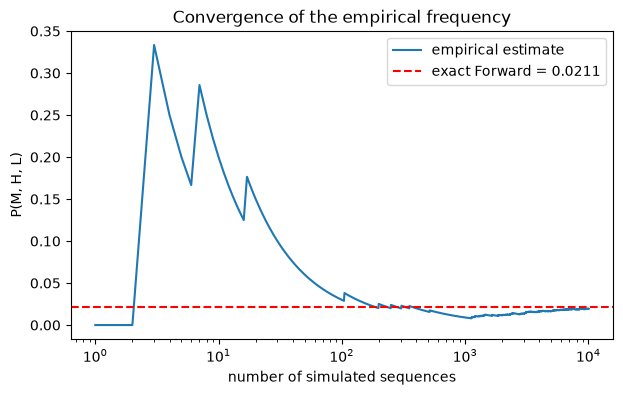

In [13]:
plt.figure(figsize=(7, 4))
plt.plot(np.arange(1, N + 1), running_estimate, label="empirical estimate")
plt.axhline(p_forward, color="red", ls="--", label=f"exact Forward = {p_forward:.4f}")
plt.xscale("log")
plt.xlabel("number of simulated sequences")
plt.ylabel("P(M, H, L)")
plt.title("Convergence of the empirical frequency")
plt.legend()
plt.savefig(FIG / "subject2_simulation.png", dpi=150, bbox_inches="tight")
plt.show()

**Comparison.** The empirical frequency is close to the exact 0.0211; the difference is of the order of
the standard error $\sqrt{p(1-p)/N}\approx0.0014$, and it shrinks as N grows (Law of Large Numbers).